# Part 3: Architecture Extension

## Imports and Settings

In [19]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from utils import *


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

set_seed(42)

Using device: cpu


## Load Data

In [20]:
X_train, y_train, X_val, y_val, X_test, y_test, train_ds, val_ds, test_ds, feature_cols, target_col, idx_to_label = load_data()

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

criterion = nn.CrossEntropyLoss()
label_names = [idx_to_label[i] for i in range(len(idx_to_label))]

## Deep MLP

Here we define a generic deep MLP for multiple uses.

In [21]:
class DeepMLP(nn.Module):
    def __init__(self, input_dim=561, hidden_dims=[64], num_classes=6, activations="relu", dropout=0.0, norm_type=None):
        super().__init__()

        if isinstance(activations, str):
            activations = [activations] * len(hidden_dims)
        elif len(activations) != len(hidden_dims):
            raise ValueError(f"Length of activations must match hidden_dims.")

        layers = []
        prev_dim = input_dim

        for h_dim, act_name in zip(hidden_dims, activations):
            layers.append(nn.Linear(prev_dim, h_dim))

            if norm_type == "batch_norm":
                layers.append(nn.BatchNorm1d(h_dim))
            elif norm_type == "layer_norm":
                layers.append(nn.LayerNorm(h_dim))

            act = act_name
            if act == "relu":
                layers.append(nn.ReLU())
            elif act == "tanh":
                layers.append(nn.Tanh())
            elif act == "sigmoid":
                layers.append(nn.Sigmoid())
            elif act == "gelu":
                layers.append(nn.GELU())
            elif act == "leaky_relu":
                layers.append(nn.LeakyReLU(0.1))
            else:
                raise ValueError("Unsupported activation.")

            if dropout > 0.0:
                layers.append(nn.Dropout(dropout))

            prev_dim = h_dim

        layers.append(nn.Linear(prev_dim, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

    def count_parameters(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

## Hidden Layer Widths

We keep the architecture at 1 hidden layer and vary the width $W \in \{32, 64, 128, 256\}$.

As tested in part 2, most activation and optimizer provides similar results. Thus, we keep the learning rate 0.001 with Adam as it performs quite well and is versatile especially with the ReLU family.

In [22]:
widths = [32, 64, 128, 256, 512, 1024]
width_results = []
width_histories = {}

for w in widths:
    model = DeepMLP(input_dim=561, hidden_dims=[w], num_classes=6, activations="relu").to(device)
    n_params = model.count_parameters()
    opt = torch.optim.Adam(model.parameters(), lr=0.001)

    t0 = time.perf_counter()
    hist = train_model(
        model, train_loader, val_loader, criterion, opt,
        n_epochs=50, device=device, early_stopping_patience=10, verbose_every=0
    )
    elapsed = time.perf_counter() - t0

    best_ep = hist["best_epoch"]
    n_eps = len(hist["train_loss"])
    time_per_ep = (elapsed / n_eps) * 1000

    train_acc = hist["train_acc"][best_ep - 1] * 100
    train_loss = hist["train_loss"][best_ep - 1]
    val_acc = hist["val_acc"][best_ep - 1] * 100
    val_loss = hist["val_loss"][best_ep - 1]
    gen_gap = train_acc - val_acc

    width_histories[f"Width {w}"] = hist
    width_results.append({
        "Hidden Width": w,
        "Parameters": n_params,
        "Best Epoch": f"{best_ep}/{n_eps}",
        "Train Acc (%)": round(train_acc, 2),
        "Train Loss": round(train_loss, 4),
        "Val Acc (%)": round(val_acc, 2),
        "Val Loss": round(val_loss, 4),
        "Gen Gap (%)": round(gen_gap, 2),
        "Time/ep (ms)": round(time_per_ep, 1)
    })
    print(f"Width {w:>3} | Params: {n_params:>6} | Val Acc: {val_acc:.2f}% | Gap: {gen_gap:.2f}%")

df_widths = pd.DataFrame(width_results)
display(df_widths)

Early stopping triggered at epoch 17. Best val loss at epoch 7.
Width  32 | Params:  18182 | Val Acc: 94.41% | Gap: 3.93%
Early stopping triggered at epoch 24. Best val loss at epoch 14.
Width  64 | Params:  36358 | Val Acc: 94.94% | Gap: 4.33%
Early stopping triggered at epoch 20. Best val loss at epoch 10.
Width 128 | Params:  72710 | Val Acc: 94.89% | Gap: 4.07%
Early stopping triggered at epoch 17. Best val loss at epoch 7.
Width 256 | Params: 145414 | Val Acc: 94.99% | Gap: 4.02%
Early stopping triggered at epoch 22. Best val loss at epoch 12.
Width 512 | Params: 290822 | Val Acc: 95.21% | Gap: 4.37%
Early stopping triggered at epoch 14. Best val loss at epoch 4.
Width 1024 | Params: 581638 | Val Acc: 94.94% | Gap: 3.44%


,Hidden Width,Parameters,Best Epoch,Train Acc (%),Train Loss,Val Acc (%),Val Loss,Gen Gap (%),Time/ep (ms)
0,32,18182,7/17,98.34,0.0581,94.41,0.1480,3.93,211.2
1,64,36358,14/24,99.27,0.0240,94.94,0.1374,4.33,288.8
2,128,72710,10/20,98.96,0.0281,94.89,0.1415,4.07,283.6
3,256,145414,7/17,99.01,0.0308,94.99,0.1419,4.02,337.0
4,512,290822,12/22,99.58,0.0138,95.21,0.1327,4.37,478.2
5,1024,581638,4/14,98.37,0.0451,94.94,0.1338,3.44,586.6


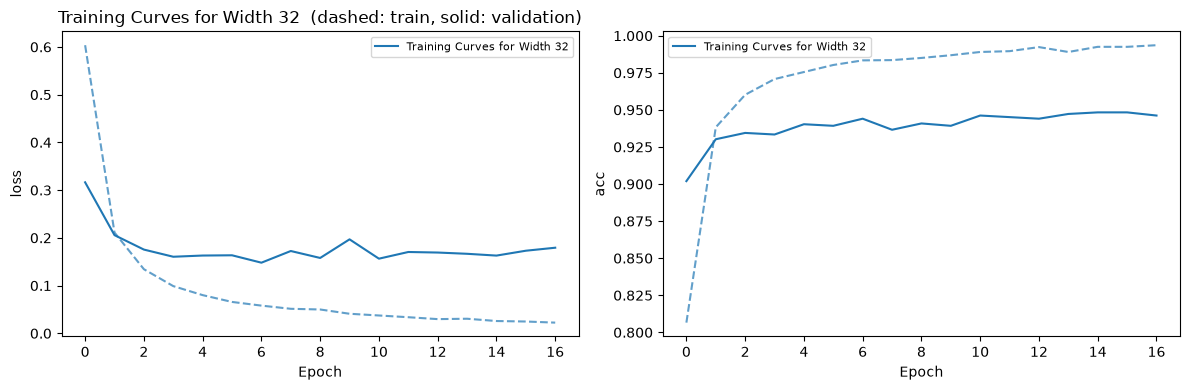

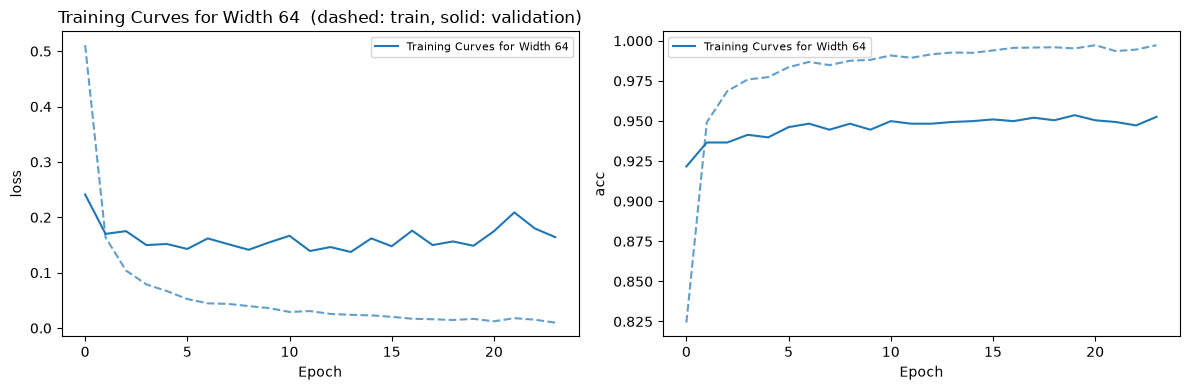

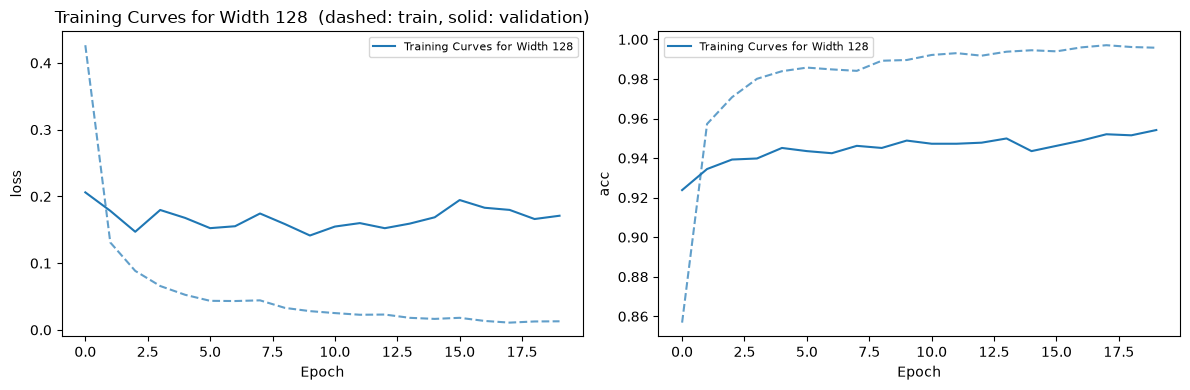

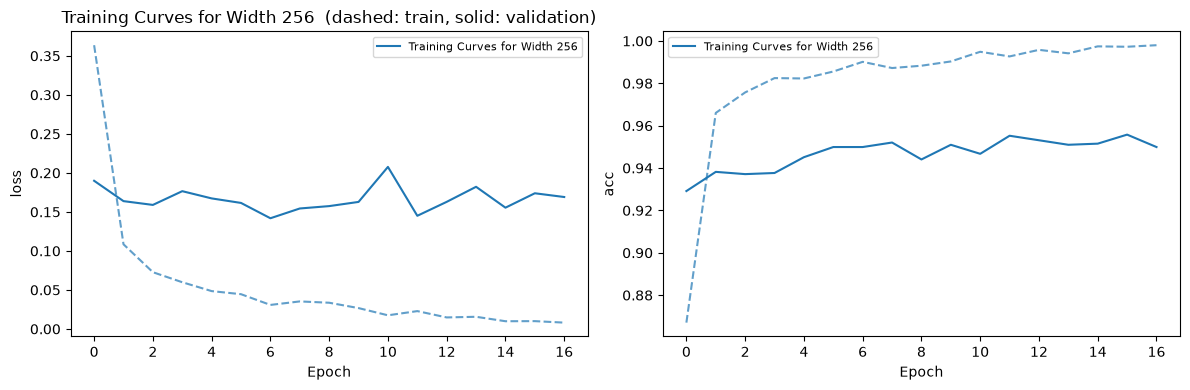

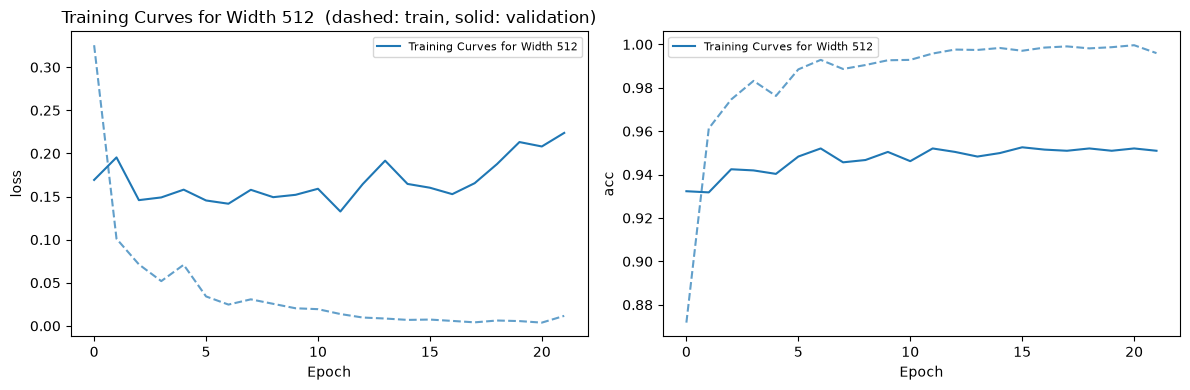

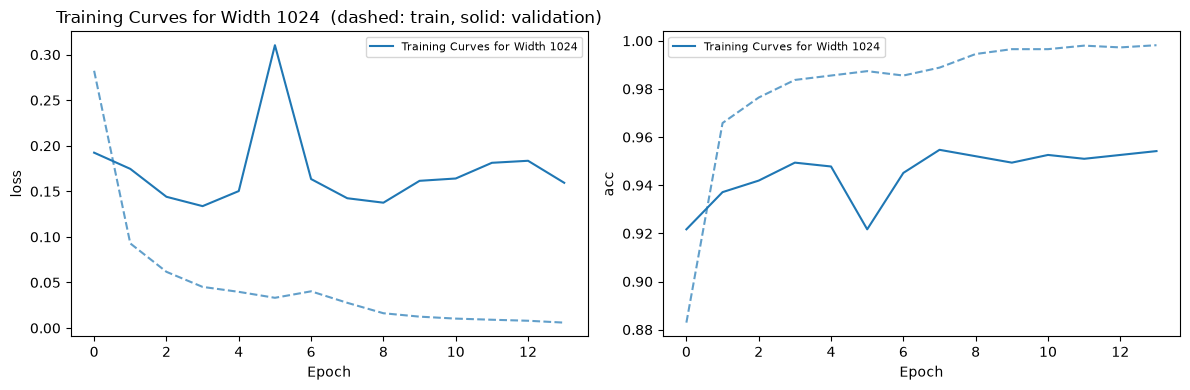

In [23]:
for w in widths:
    plot_curves(f"Training Curves for Width {w}", width_histories[f"Width {w}"])

The training loss converges quickly within a few epoch to 0. This is a clear sign of overfitting, notably because:
- even with the width-32 model, there are already around 18,000 parameters, more than the number of training samples.
- The validation errors saturate, thus generalization gap do not change between models of different width.

=> Thus, **regularization is needed**.

Compute time increases as the width increases as expected.

## Deeper Networks and Regularization

We now evaluate deeper networks with different activations.

As stated above, regularization is required to make the model not overfit, adding more layers won't solve this. So to pick some candidates, we add weight decay to our model.

As informed by results of the shallow network, we could try having Tanh activation in the first layer. As the features are 0-centered, Tanh preserves both positive and negative features without discarding negative values on the first pass like ReLU.

In the deeper layers, the ReLU family is probably better as its gradient does not saturate, prevents vanishing gradients, speeds up convergence, and induces sparse representations.

Early stopping triggered at epoch 13. Best val loss at epoch 3.
[(ReLU)              ] Seed   42 | Params:  72710 | Val Acc: 94.30% | Gap: 3.13%
Early stopping triggered at epoch 19. Best val loss at epoch 9.
[(ReLU)              ] Seed  123 | Params:  72710 | Val Acc: 94.89% | Gap: 4.24%
Early stopping triggered at epoch 13. Best val loss at epoch 3.
[(ReLU)              ] Seed  999 | Params:  72710 | Val Acc: 94.46% | Gap: 2.98%
Early stopping triggered at epoch 16. Best val loss at epoch 6.
[(ReLU)              ] Seed 1000 | Params:  72710 | Val Acc: 94.67% | Gap: 3.99%
Early stopping triggered at epoch 15. Best val loss at epoch 5.
[(ReLU)              ] Seed 2026 | Params:  72710 | Val Acc: 94.73% | Gap: 3.47%
Early stopping triggered at epoch 14. Best val loss at epoch 4.
[(ReLU) x2           ] Seed   42 | Params:  80582 | Val Acc: 94.83% | Gap: 2.87%
Early stopping triggered at epoch 13. Best val loss at epoch 3.
[(ReLU) x2           ] Seed  123 | Params:  80582 | Val Acc: 94.35

,Architecture,Hidden Layout,Norm,Dropout,Weight Decay,Parameters,Val Accuracy (Mean ± Std) (%),Val Macro F1 (Mean ± Std) (%),Gen Gap (Mean) (%),Avg Time/ep (ms)
0,(GELU) x4,"[256, 128, 64, 32]",none,0.0,0.0001,187302,95.38 ± 0.28,95.84 ± 0.24,2.98,356.3
1,(ReLU) x4,"[256, 128, 64, 32]",none,0.0,0.0001,187302,95.24 ± 0.22,95.72 ± 0.19,2.97,330.6
2,(ReLU) x3,"[256, 128, 64]",none,0.0,0.0001,185414,95.28 ± 0.23,95.71 ± 0.21,2.97,490.4
3,(GELU) x3,"[256, 128, 64]",none,0.0,0.0001,185414,95.15 ± 0.56,95.61 ± 0.53,2.86,324.4
4,(ReLU) x2,"[128, 64]",none,0.0,0.0001,80582,95.02 ± 0.53,95.53 ± 0.44,3.13,408.0
5,(Tanh) - (ReLU) x2,"[256, 128, 64]",none,0.0,0.0001,185414,94.93 ± 0.38,95.38 ± 0.32,3.36,467.1
6,(Tanh) - (ReLU),"[128, 64]",none,0.0,0.0001,80582,94.66 ± 0.40,95.20 ± 0.37,2.97,387.7
7,(Tanh) - (ReLU) x3,"[256, 128, 64, 32]",none,0.0,0.0001,187302,94.63 ± 0.74,95.18 ± 0.64,3.79,297.9
8,(ReLU),[128],none,0.0,0.0001,72710,94.61 ± 0.23,95.18 ± 0.21,3.56,356.2


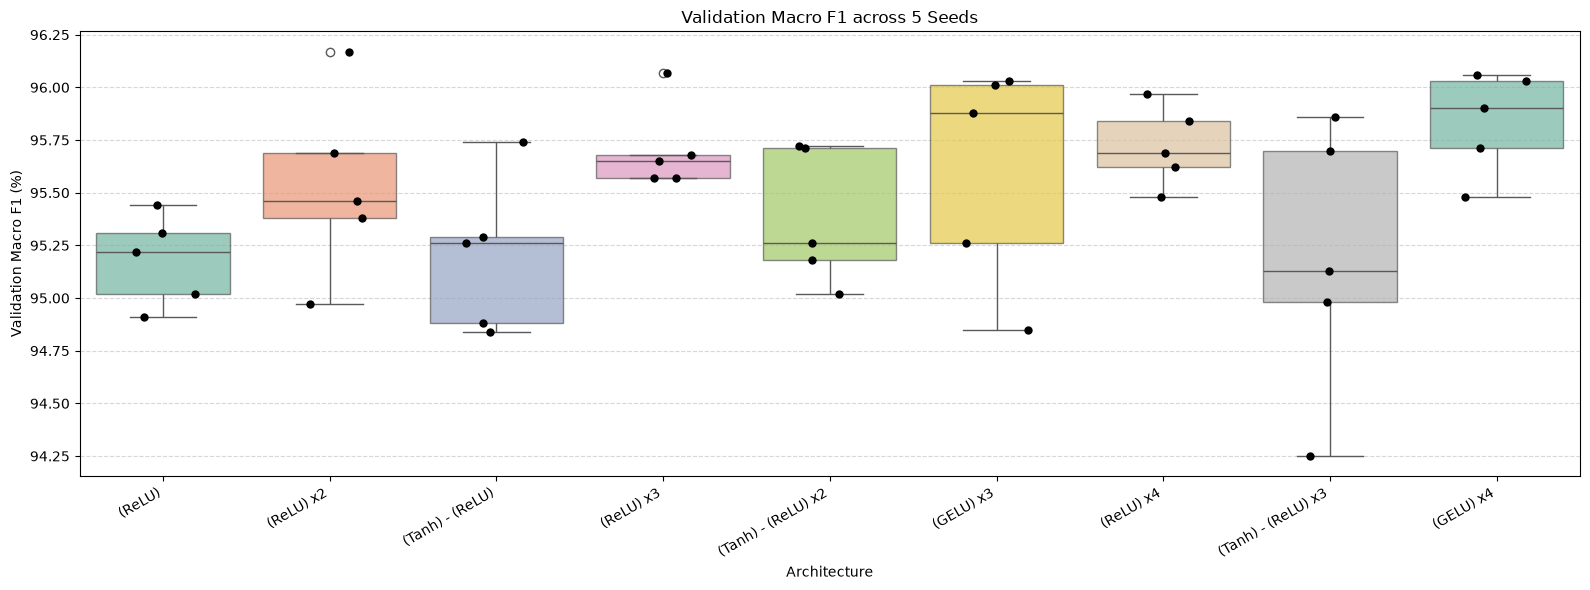

In [24]:
SEEDS = [42, 123, 999, 1000, 2026]
depth_configs = [
    # 1 layer reference
    {"name": "(ReLU)", "dims": [128], "acts": ["relu"]},
    # 2 layers
    {"name": "(ReLU) x2", "dims": [128, 64], "acts": ["relu", "relu"]},
    {"name": "(Tanh) - (ReLU)", "dims": [128, 64], "acts": ["tanh", "relu"]},
    # 3 layers
    {"name": "(ReLU) x3", "dims": [256, 128, 64], "acts": ["relu", "relu", "relu"]},
    {"name": "(Tanh) - (ReLU) x2", "dims": [256, 128, 64], "acts": ["tanh", "relu", "relu"]},
    {"name": "(GELU) x3", "dims": [256, 128, 64], "acts": ["gelu", "gelu", "gelu"]},
    # 4 layers
    {"name": "(ReLU) x4", "dims": [256, 128, 64, 32], "acts": ["relu", "relu", "relu", "relu"]},
    {"name": "(Tanh) - (ReLU) x3", "dims": [256, 128, 64, 32], "acts": ["tanh", "relu", "relu", "relu"]},
    {"name": "(GELU) x4", "dims": [256, 128, 64, 32], "acts": ["gelu", "gelu", "gelu", "gelu"]},
]


def run_all_configs(
        configs, seeds,
        train_loader=train_loader, val_loader=val_loader, criterion=criterion, device=device,
        early_stopping_patience=10, n_epochs=100
):
    all_seed_runs = []
    histories = {}

    for cfg in configs:
        histories[cfg["name"]] = {}

        for seed in seeds:
            set_seed(seed)

            model = DeepMLP(
                hidden_dims=cfg["dims"],
                activations=cfg["acts"],
                dropout=cfg.get("dropout", 0.0),
                norm_type=cfg.get("norm_type", None)
            ).to(device)
            opt = torch.optim.AdamW(model.parameters(), lr=cfg.get("lr", 0.001), weight_decay=cfg.get("weight_decay", 0.0001))

            n_params = model.count_parameters()
            t0 = time.perf_counter()
            hist = train_model(
                model, train_loader, val_loader, criterion, opt,
                n_epochs=n_epochs, device=device, early_stopping_patience=early_stopping_patience, verbose_every=0
            )
            hist["model"] = model
            elapsed = time.perf_counter() - t0

            best_ep = hist["best_epoch"]
            n_eps = len(hist["train_loss"])
            time_per_ep = (elapsed / n_eps) * 1000

            train_acc = hist["train_acc"][best_ep - 1] * 100
            train_loss = hist["train_loss"][best_ep - 1]
            val_acc = hist["val_acc"][best_ep - 1] * 100
            val_loss = hist["val_loss"][best_ep - 1]
            val_f1 = hist["val_f1"][best_ep - 1] * 100
            gen_gap = train_acc - val_acc

            run_data = {
                "Architecture": cfg["name"],
                "Hidden Layout": str(cfg["dims"]),
                "Norm": cfg.get("norm_type", "none"),
                "Dropout": cfg.get("dropout", 0.0),
                "Weight Decay": cfg.get("weight_decay", 0.0001),
                "Seed": seed,
                "Parameters": n_params,
                "Best Epoch": f"{best_ep}/{n_eps}",
                "Train Acc (%)": round(train_acc, 2),
                "Train Loss": round(train_loss, 4),
                "Val Acc (%)": round(val_acc, 2),
                "Val Loss": round(val_loss, 4),
                "Val Macro F1 (%)": round(val_f1, 2),
                "Gen Gap (%)": round(gen_gap, 2),
                "Time/ep (ms)": round(time_per_ep, 1)
            }

            all_seed_runs.append(run_data)
            histories[cfg["name"]][seed] = hist

            print(f"[{cfg['name']:<20}] Seed {seed:>4} | Params: {n_params:>6} | Val Acc: {val_acc:.2f}% | Gap: {gen_gap:.2f}%")

    df_all_runs = pd.DataFrame(all_seed_runs)

    summary_rows = []
    for name, group in df_all_runs.groupby("Architecture", sort=False):
        accs = group["Val Acc (%)"]
        f1s = group["Val Macro F1 (%)"]
        gaps = group["Gen Gap (%)"]
        times = group["Time/ep (ms)"]
        layout = group["Hidden Layout"].iloc[0]
        params = group["Parameters"].iloc[0]

        summary_rows.append({
            "Architecture": name,
            "Hidden Layout": layout,
            "Norm": group["Norm"].iloc[0],
            "Dropout": group["Dropout"].iloc[0],
            "Weight Decay": group["Weight Decay"].iloc[0],
            "Parameters": params,
            "Val Accuracy (Mean ± Std) (%)": f"{accs.mean():.2f} ± {accs.std():.2f}",
            "Val Macro F1 (Mean ± Std) (%)": f"{f1s.mean():.2f} ± {f1s.std():.2f}",
            "Gen Gap (Mean) (%)": f"{gaps.mean():.2f}",
            "Avg Time/ep (ms)": f"{times.mean():.1f}",
            "_sort_f1": f1s.mean()
        })

    df_summary = pd.DataFrame(summary_rows) \
        .sort_values(by="_sort_f1", ascending=False).drop(columns=["_sort_f1"]).reset_index(drop=True)

    return df_all_runs, df_summary, histories


df_all_runs, df_summary, _ = run_all_configs(depth_configs, SEEDS)

display(df_summary)

plt.figure(figsize=(16, 6))
sns.boxplot(
    data=df_all_runs, x="Architecture", y="Val Macro F1 (%)",
    hue="Architecture", palette="Set2", legend=False, boxprops=dict(alpha=0.7)
)
sns.stripplot(data=df_all_runs, x="Architecture", y="Val Macro F1 (%)", color="black", size=6, jitter=0.2)
plt.title(f"Validation Macro F1 across {len(SEEDS)} Seeds")
plt.xlabel("Architecture")
plt.ylabel("Validation Macro F1 (%)")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Adding regularization does give our models slightly higher validation accuracy, through multiple seeds, we keep the configuration GELU x4 (best performance). Note: I did try to run Grid search with Tanh - ReLU x3 (high median) also but it isn't as good and grid search is already slow as is so I removed it.

### Grid Search

We will perform a random grid search on the regularization hyperparameters and the architectures chosen:
- Dropout: $\{0.0, 0.1, 0.3, 0.5\}$
- Weight Decay: $\{0.0, 10^{-4}, 10^{-3}, 10^{-2}\}$ via AdamW
- Normalization: None, Batch Normalization, Layer Normalization
- Early Stopping: Monitored on validation loss

With each run in a few different seeds to make sure we don't miss any configuration due to chance.

In [25]:
top_architectures = [
    {"name": "(GELU) x4", "dims": [256, 128, 64, 32], "acts": ["gelu", "gelu", "gelu", "gelu"]},
]

param_grid = {
    "dropout": [0.0, 0.1, 0.3, 0.5],
    "weight_decay": [0.0, 1e-4, 1e-3, 1e-2],
    "norm_type": [None, "batch_norm", "layer_norm"],
}

set_seed(42)
N_TRIALS = 15
search_configs = []

while len(search_configs) < N_TRIALS:
    arch = random.choice(top_architectures)
    drop = random.choice(param_grid["dropout"])
    wd = random.choice(param_grid["weight_decay"])
    norm = random.choice(param_grid["norm_type"])
    t_id = len(search_configs) + 1
    search_configs.append({
        "name": f"{arch['name']} [{norm}] [{drop}] [{wd}]",
        "arch_name": arch["name"],
        "dims": arch["dims"],
        "acts": arch["acts"],
        "dropout": drop,
        "weight_decay": wd,
        "norm_type": norm,
    })

df_search_runs, df_search_summary, histories = run_all_configs(search_configs, seeds=SEEDS)

display(df_search_summary)

Early stopping triggered at epoch 14. Best val loss at epoch 4.
[(GELU) x4 [None] [0.0] [0.001]] Seed   42 | Params: 187302 | Val Acc: 95.47% | Gap: 2.10%
Early stopping triggered at epoch 19. Best val loss at epoch 9.
[(GELU) x4 [None] [0.0] [0.001]] Seed  123 | Params: 187302 | Val Acc: 95.47% | Gap: 3.18%
Early stopping triggered at epoch 15. Best val loss at epoch 5.
[(GELU) x4 [None] [0.0] [0.001]] Seed  999 | Params: 187302 | Val Acc: 94.94% | Gap: 2.91%
Early stopping triggered at epoch 15. Best val loss at epoch 5.
[(GELU) x4 [None] [0.0] [0.001]] Seed 1000 | Params: 187302 | Val Acc: 95.26% | Gap: 2.92%
Early stopping triggered at epoch 15. Best val loss at epoch 5.
[(GELU) x4 [None] [0.0] [0.001]] Seed 2026 | Params: 187302 | Val Acc: 94.73% | Gap: 2.88%
Early stopping triggered at epoch 16. Best val loss at epoch 6.
[(GELU) x4 [layer_norm] [0.1] [0.0]] Seed   42 | Params: 188262 | Val Acc: 95.31% | Gap: 1.80%
Early stopping triggered at epoch 25. Best val loss at epoch 15.
[

,Architecture,Hidden Layout,Norm,Dropout,Weight Decay,Parameters,Val Accuracy (Mean ± Std) (%),Val Macro F1 (Mean ± Std) (%),Gen Gap (Mean) (%),Avg Time/ep (ms)
0,(GELU) x4 [batch_norm] [0.0] [0.0001],"[256, 128, 64, 32]",batch_norm,0.0,0.0001,188262,97.02 ± 0.58,97.26 ± 0.53,1.58,862.1
1,(GELU) x4 [batch_norm] [0.1] [0.0],"[256, 128, 64, 32]",batch_norm,0.1,0.0000,188262,96.72 ± 0.40,97.02 ± 0.38,1.79,907.8
2,(GELU) x4 [batch_norm] [0.0] [0.001],"[256, 128, 64, 32]",batch_norm,0.0,0.0010,188262,96.74 ± 0.26,97.00 ± 0.24,1.84,867.2
3,(GELU) x4 [layer_norm] [0.3] [0.0001],"[256, 128, 64, 32]",layer_norm,0.3,0.0001,188262,95.96 ± 0.33,96.33 ± 0.30,2.75,798.4
4,(GELU) x4 [layer_norm] [0.5] [0.0],"[256, 128, 64, 32]",layer_norm,0.5,0.0000,188262,95.65 ± 0.41,96.05 ± 0.36,-0.26,780.3
5,(GELU) x4 [layer_norm] [0.1] [0.0],"[256, 128, 64, 32]",layer_norm,0.1,0.0000,188262,95.65 ± 0.30,96.00 ± 0.29,2.37,860.3
6,(GELU) x4 [None] [0.1] [0.01],"[256, 128, 64, 32]",NaN,0.1,0.0100,187302,95.53 ± 0.69,95.91 ± 0.61,2.48,644.8
7,(GELU) x4 [None] [0.5] [0.001],"[256, 128, 64, 32]",NaN,0.5,0.0010,187302,95.48 ± 0.38,95.90 ± 0.35,-0.37,662.4
8,(GELU) x4 [layer_norm] [0.1] [0.0001],"[256, 128, 64, 32]",layer_norm,0.1,0.0001,188262,95.46 ± 0.40,95.86 ± 0.37,3.29,817.1
9,(GELU) x4 [None] [0.3] [0.0],"[256, 128, 64, 32]",NaN,0.3,0.0000,187302,95.40 ± 0.46,95.83 ± 0.41,1.55,617.5


From this result, it seems that batch norm is very effective. The first place is quite significantly (qualitatively) different from the second place. We keep the 3 best for the next analyses:
- (GELU) x4 [batch_norm] [0.0] [0.0001]
- (GELU) x4 [batch_norm] [0.1] [0.0]
- (GELU) x4 [batch_norm] [0.0] [0.001].

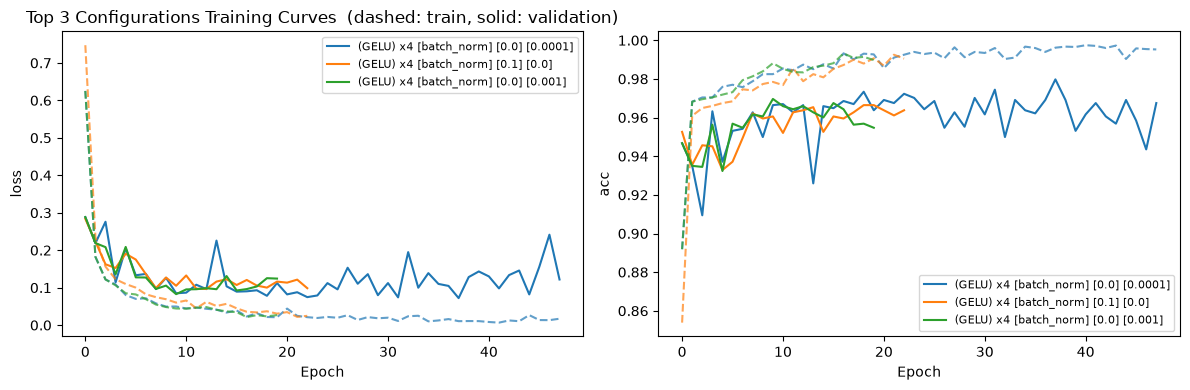

(GELU) x4 [batch_norm] [0.0] [0.0001]'s best epoch: 38
(GELU) x4 [batch_norm] [0.1] [0.0]'s best epoch: 13
(GELU) x4 [batch_norm] [0.0] [0.001]'s best epoch: 10


In [26]:
top_config_names = df_search_summary["Architecture"].head(3).tolist()
top_3_configs = { cfg_name : histories[cfg_name][42] for cfg_name in top_config_names }

plot_curves("Top 3 Configurations Training Curves", top_3_configs)

for cfg_name, cfg in top_3_configs.items():
    print(f"{cfg_name}'s best epoch: {cfg['best_epoch']}")

Our model's generalization gap is less than 2% so seems fine, no overfitting or underfitting. Although the best model's learning rate produces quite noisy validation set which we could reduce.

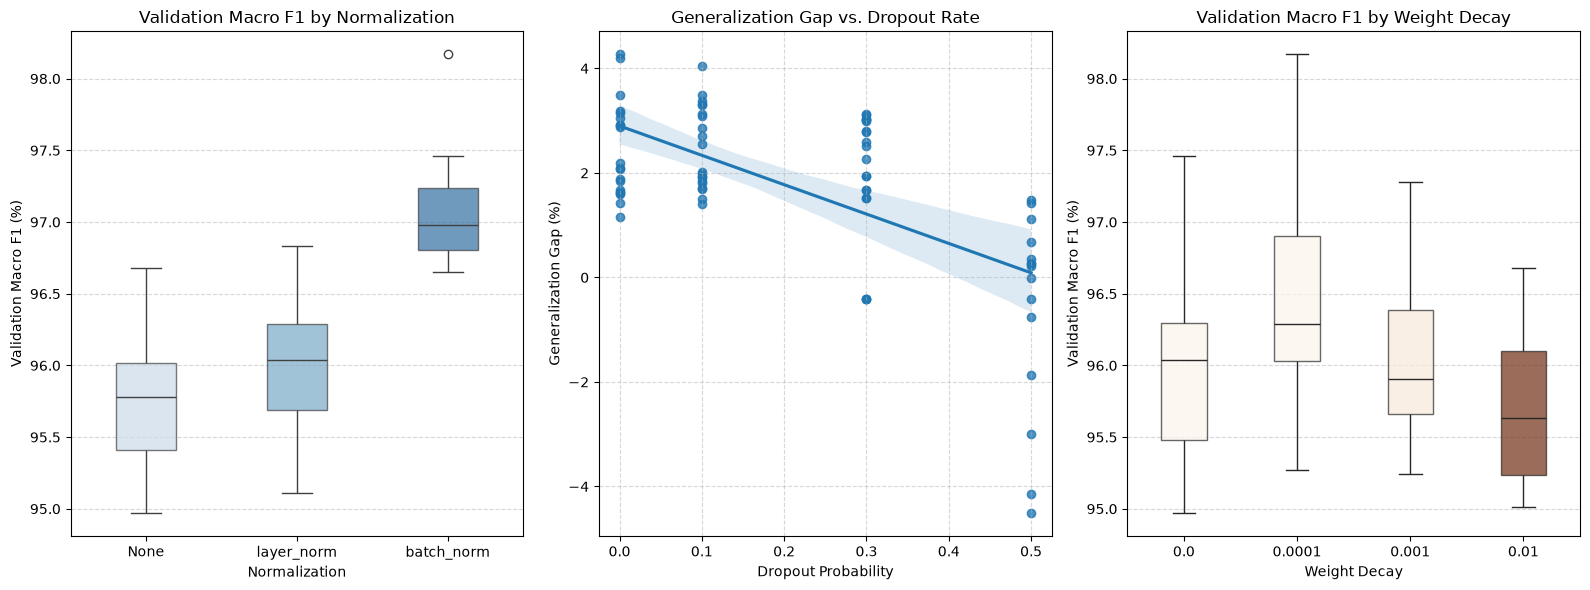

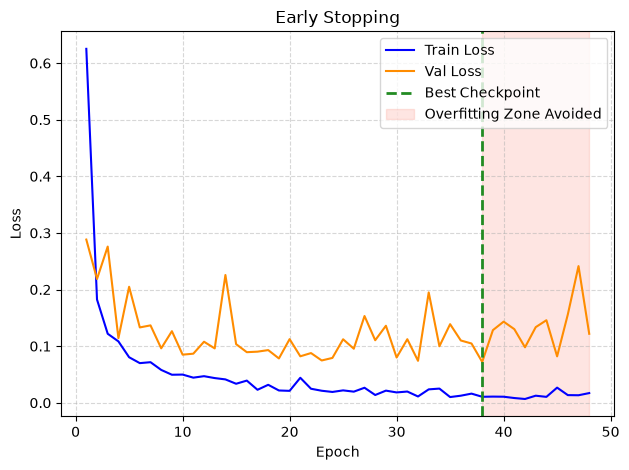

In [27]:
df_search_runs["Norm"] = df_search_runs["Norm"].fillna("None")

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

# Validation Macro F1 by Normalization Type
sns.boxplot(
    data=df_search_runs, x="Norm", y="Val Macro F1 (%)",
    hue="Norm", palette="Blues", ax=axes[0], legend=False, width=0.4, boxprops=dict(alpha=0.7)
)
axes[0].set_title("Validation Macro F1 by Normalization")
axes[0].set_xlabel("Normalization")
axes[0].set_ylabel("Validation Macro F1 (%)")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Generalization Gap by Dropout Rate
sns.regplot(data=df_search_runs, x="Dropout", y="Gen Gap (%)", ax=axes[1])
axes[1].set_title("Generalization Gap vs. Dropout Rate")
axes[1].set_xlabel("Dropout Probability")
axes[1].set_ylabel("Generalization Gap (%)")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Validation Macro F1 by Weight Decay
sns.boxplot(
    data=df_search_runs, x="Weight Decay", y="Val Macro F1 (%)",
    hue="Weight Decay", palette="Oranges", ax=axes[2], legend=False, width=0.4, boxprops=dict(alpha=0.7)
)
axes[2].set_title("Validation Macro F1 by Weight Decay")
axes[2].set_xlabel(r"Weight Decay")
axes[2].set_ylabel("Validation Macro F1 (%)")
axes[2].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Early Stopping (Overfitting Zone Avoided)
top_cfg_name = df_search_summary.iloc[0]["Architecture"]
top_hist = histories[top_cfg_name][42]
best_epoch = top_hist["best_epoch"]
total_epochs = len(top_hist["train_loss"])
epochs_range = np.arange(1, total_epochs + 1)

plt.plot(epochs_range, top_hist["train_loss"], label="Train Loss", color="blue")
plt.plot(epochs_range, top_hist["val_loss"], label="Val Loss", color="darkorange")
plt.axvline(best_epoch, color="forestgreen", ls="--", lw=2, label=f"Best Checkpoint")
plt.axvspan(best_epoch, total_epochs, color="salmon", alpha=0.2, label="Overfitting Zone Avoided")
plt.title("Early Stopping")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In term of generalization, we can see that:
- Batch norm improves validation by a lot compared to none and layer norm. It is kind of expected that it beats layer norm as layer norm is normally used for sequential data.
- Dropout is very effective as controlling the generalization gap by forcing neurons to learn independent feature representation. This does not always means better generalization though.
- Weight decay gives a concave shape on validation loss as expected and the value of 0.0001 is the best.
- Early stopping halt training before overfitting or plateauing.

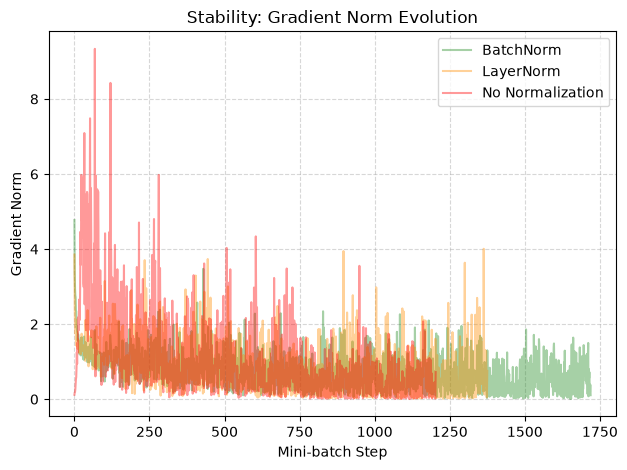

In [28]:
# Compare gradient norms of between normalization methods
bn_key = [k for k in histories.keys() if "batch_norm" in k][0]
ln_key = [k for k in histories.keys() if "layer_norm" in k][0]
none_key = [k for k in histories.keys() if "None" in k][0]
bn_gn = histories[bn_key][42]["grad_norms"]
ln_gn = histories[ln_key][42]["grad_norms"]
none_gn = histories[none_key][42]["grad_norms"]

plt.plot(bn_gn, alpha=0.4, color="forestgreen", label="BatchNorm")
plt.plot(ln_gn, alpha=0.4, color="darkorange", label="LayerNorm")
plt.plot(none_gn, alpha=0.4, color="red", label="No Normalization")

plt.title("Stability: Gradient Norm Evolution")
plt.xlabel("Mini-batch Step")
plt.ylabel("Gradient Norm")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In term of stability: Batch norm is quite stable. Layer norm is also but a less so. We can also see that normalization eliminates vanishing/exploding gradients and smooths the loss landscape.

## Final Test

We will test 2 approaches:
- Keep the same train and validation sets for early stopping.
- Retrain the 3 best configuration on the whole training + validation dataset (stop at the previous best early stopping epoch, we could try scaling it up as training on more data will regularize the model but we will not test that here for simplicity). Training on more data like this should further regularize the model and hopefully increases accuracy.

We do not restandardize the data on both train and validation set for simplicity, but in reality, it could be tested.

,Architecture,Parameters,Test Accuracy (Mean ± Std) (%),Test Macro F1 (Mean ± Std) (%),Gen Gap (Mean) (%),Avg Time/ep (ms)
0,(GELU) x4 [batch_norm] [0.0] [0.0001] (Fixed E...,188262,94.28 ± 1.00,94.26 ± 1.06,5.21,1207.0
1,(GELU) x4 [batch_norm] [0.0] [0.0001] (Early S...,188262,94.74 ± 0.92,94.68 ± 0.96,3.86,544.6
2,(GELU) x4 [batch_norm] [0.1] [0.0] (Fixed Epochs),188262,95.04 ± 1.15,95.02 ± 1.17,3.30,757.0
3,(GELU) x4 [batch_norm] [0.1] [0.0] (Early Stop...,188262,94.27 ± 0.41,94.26 ± 0.45,4.24,716.7
4,(GELU) x4 [batch_norm] [0.0] [0.001] (Fixed Ep...,188262,93.76 ± 1.40,93.72 ± 1.42,4.62,1199.4
5,(GELU) x4 [batch_norm] [0.0] [0.001] (Early St...,188262,94.20 ± 0.60,94.21 ± 0.63,4.37,832.4
6,ReLU (Fixed Epochs),36358,93.91 ± 0.55,93.92 ± 0.57,5.12,301.5
7,ReLU (Early Stopping),36358,93.30 ± 0.19,93.32 ± 0.18,5.54,221.1
8,Logistic Regression,None,95.66 ± 0.00,95.65 ± 0.00,4.11,None


Top Performing Run: (GELU) x4 [batch_norm] [0.0] [0.0001] (Early Stopping) | Seed 42
Test Accuracy: 96.20% | Test Macro F1: 96.15% | Gap: 3.42%
                    precision    recall  f1-score   support

            LAYING     0.9963    1.0000    0.9981       537
           SITTING     0.9795    0.8778    0.9259       491
          STANDING     0.9016    0.9812    0.9397       532
           WALKING     0.9724    0.9940    0.9831       496
WALKING_DOWNSTAIRS     0.9509    0.9690    0.9599       420
  WALKING_UPSTAIRS     0.9802    0.9448    0.9622       471

          accuracy                         0.9620      2947
         macro avg     0.9635    0.9611    0.9615      2947
      weighted avg     0.9633    0.9620    0.9618      2947



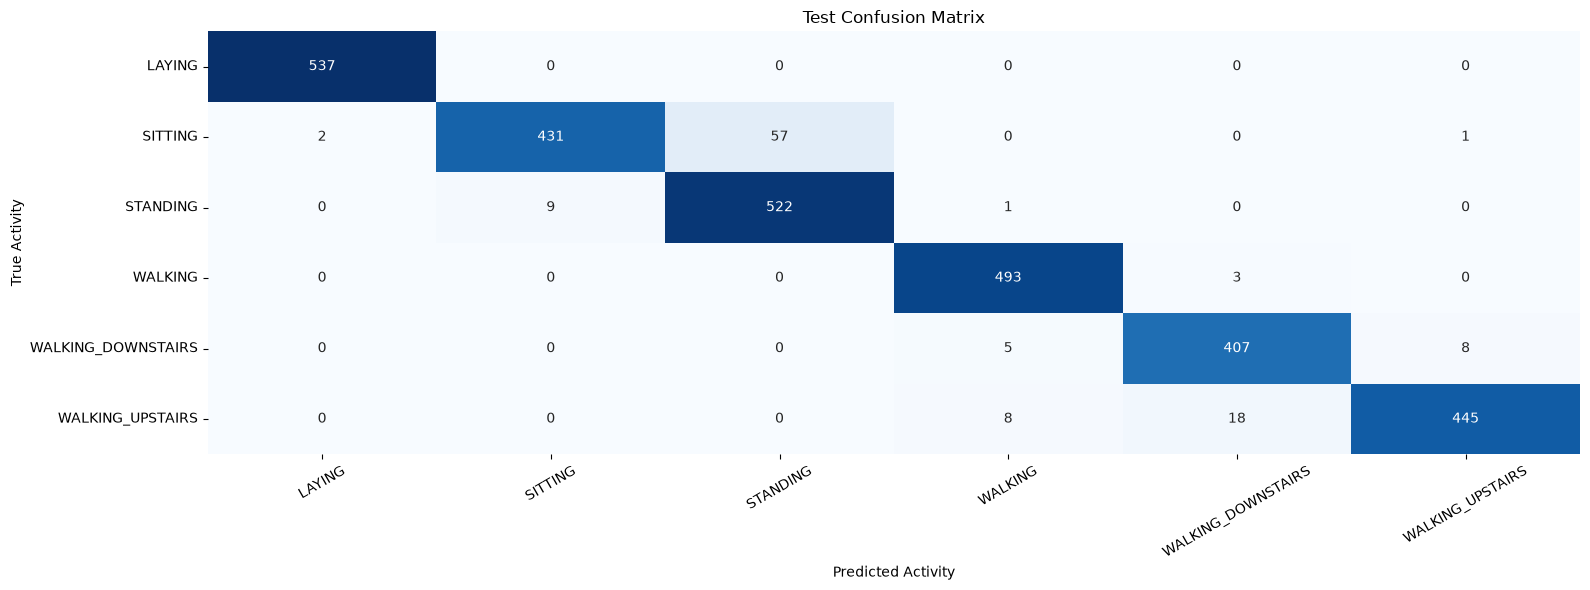

In [30]:
from torch.utils.data import ConcatDataset
train_val_ds = ConcatDataset([train_ds, val_ds])
train_val_loader = DataLoader(train_val_ds, batch_size=BATCH_SIZE, shuffle=True)

semi_final_configs = [
    {
        "name": "(GELU) x4 [batch_norm] [0.0] [0.0001]",
        "dims": [256, 128, 64, 32],
        "acts": ["gelu", "gelu", "gelu", "gelu"],
        "norm_type": "batch_norm",
        "dropout": 0.0,
        "weight_decay": 0.0001,
        "fixed_epochs": 38
    },
    {
        "name": "(GELU) x4 [batch_norm] [0.1] [0.0]",
        "dims": [256, 128, 64, 32],
        "acts": ["gelu", "gelu", "gelu", "gelu"],
        "norm_type": "batch_norm",
        "dropout": 0.1,
        "weight_decay": 0.0,
        "fixed_epochs": 13
    },
    {
        "name": "(GELU) x4 [batch_norm] [0.0] [0.001]",
        "dims": [256, 128, 64, 32],
        "acts": ["gelu", "gelu", "gelu", "gelu"],
        "norm_type": "batch_norm",
        "dropout": 0.0,
        "weight_decay": 0.001,
        "fixed_epochs": 10
    },
    # Best config from shallow network
    {
        "name": "ReLU",
        "dims": [64],
        "acts": ["relu"],
        "norm_type": None,
        "dropout": 0.0,
        "weight_decay": 0.0,
        "fixed_epochs": 14
    },
]

final_configs = []
for cfg in semi_final_configs:
    fixed_epoch_config = cfg.copy()
    fixed_epoch_config["name"] += " (Fixed Epochs)"
    final_configs.append(fixed_epoch_config)

    early_stopping_config = cfg.copy()
    early_stopping_config["name"] += " (Early Stopping)"
    final_configs.append(early_stopping_config)

test_run_dfs = []
test_summary_dfs = []
test_histories = {}
for cfg in final_configs:
    epoch_fixed = "Fixed Epochs" in cfg["name"]
    if epoch_fixed:
        epochs = cfg["fixed_epochs"]
        df_runs, df_sum, hists = run_all_configs(
            [cfg], SEEDS, train_loader=train_val_loader, val_loader=test_loader,
            early_stopping_patience=None, n_epochs=epochs
        )
    else:
        df_runs, df_sum, hists = run_all_configs(
            [cfg], SEEDS, train_loader=train_loader, val_loader=val_loader
        )

    test_accs, test_f1s = [], []
    for seed in SEEDS:
        m = hists[cfg["name"]][seed]["model"]
        _, t_acc, t_f1, _, _ = evaluate_model(m, test_loader, criterion, device=device)
        test_accs.append(round(t_acc * 100, 2))
        test_f1s.append(round(t_f1 * 100, 2))

    df_runs["Test Acc (%)"] = test_accs
    df_runs["Test Macro F1 (%)"] = test_f1s
    df_runs["Gen Gap (%)"] = (df_runs["Train Acc (%)"] - df_runs["Test Acc (%)"]).round(2)
    df_sum["Test Accuracy (Mean ± Std) (%)"] = f"{pd.Series(test_accs).mean():.2f} ± {pd.Series(test_accs).std():.2f}"
    df_sum["Test Macro F1 (Mean ± Std) (%)"] = f"{pd.Series(test_f1s).mean():.2f} ± {pd.Series(test_f1s).std():.2f}"
    df_sum["Gen Gap (Mean) (%)"] = f"{df_runs['Gen Gap (%)'].mean():.2f}"

    test_run_dfs.append(df_runs)
    test_summary_dfs.append(df_sum)
    test_histories.update(hists)

df_test_runs = pd.concat(test_run_dfs, ignore_index=True)
df_test_summary = pd.concat(test_summary_dfs, ignore_index=True)

lr_baseline = pd.DataFrame([{
    "Architecture": "Logistic Regression",
    "Parameters": "None",
    "Test Accuracy (Mean ± Std) (%)": "95.66 ± 0.00",
    "Test Macro F1 (Mean ± Std) (%)": "95.65 ± 0.00",
    "Gen Gap (Mean) (%)": "4.11",
    "Avg Time/ep (ms)": "None"
}])

df_display = pd.concat([
    df_test_summary[[
        "Architecture", "Parameters", "Test Accuracy (Mean ± Std) (%)", "Test Macro F1 (Mean ± Std) (%)",
        "Gen Gap (Mean) (%)", "Avg Time/ep (ms)"
    ]],
    lr_baseline
], ignore_index=True)
display(df_display)

best_run = df_test_runs.sort_values(by="Test Macro F1 (%)", ascending=False).iloc[0]
best_arch = best_run["Architecture"]
best_seed = int(best_run["Seed"])
best_f1 = best_run["Test Macro F1 (%)"]
best_acc = best_run["Test Acc (%)"]

print(f"Top Performing Run: {best_arch} | Seed {best_seed}")
print(f"Test Accuracy: {best_acc:.2f}% | Test Macro F1: {best_f1:.2f}% | Gap: {best_run['Gen Gap (%)']:.2f}%")

best_model = test_histories[best_arch][best_seed]["model"]
_, _, _, best_test_preds, best_test_targets = evaluate_model(
    best_model, test_loader, criterion, device=device
)

print(classification_report(best_test_targets, best_test_preds, target_names=label_names, digits=4))

cm_counts = confusion_matrix(best_test_targets, best_test_preds)
cm_norm = cm_counts.astype("float") / cm_counts.sum(axis=1)[:, np.newaxis] * 100
fig, axes = plt.subplots(1, 1, figsize=(16, 6))
sns.heatmap(
    cm_counts, annot=True, fmt="d", cmap="Blues", ax=axes,
    xticklabels=label_names, yticklabels=label_names, cbar=False
)
axes.set_title(f"Test Confusion Matrix")
axes.set_xlabel("Predicted Activity")
axes.set_ylabel("True Activity")
axes.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

It is clear that the validation results (best model averages F1 97.26 ± 0.53) are optimistic compared to the test ones (best model averages F1 95.02 ± 1.17) as we are allowed to pick the best performing model in the validation case. 

The best model architecture also changes. This is likely due to the learning rate being slightly more unstable for our best model chosen in the validation phase. This is also certified by how its early stopping version does better than its fixed epoch version.

Compared to the shallow network baseline, the deeper ones perform better. However, in general, they do not perform better than the simple logistic regression (in validation and in test). This is could be due to their huge number of parameters compared to the dataset dimensionality overfitting that regularization cannot fix entirely (through our random grid search). Our best deep network configuration does beat logistic regression (96.20%) but remains statistically insignificant.

The primary source of classification error is mutual confusion between `SITTING` and `STANDING`. This confusion is plausible physically as both are static postures characterized by virtually zero kinetic energy (some features related to acceleration are approximately 0 or constant). Because the phone is wore on the waist, the angle of the phone can be nearly identical whether the volunteer is sitting or standing.

`LAYING` is classified with near-perfect accuracy. When lying down, the gravitational acceleration vector shifts by 90 degrees, creating an unmistakable orientation signature.

Dynamic Activities (`WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS`) are cleanly separated from static ones due to body acceleration and gyroscope variance.

The simple distinctions between these activities could be why the linear nature of logistic regression already worked quite well. And as its loss is convex, it can more easily find a good minimum unlike neural networks.

Confusion occurs between `WALKING`, `WALKING_UPSTAIRS` and `WALKING_DOWNSTAIRS` due to overlapping poses in some windows, differing primarily in subtle vertical acceleration impulse peaks.

## Interpretability and Dimensionality Reduction

As neural networks (and some other classification methods) learn to find a transformation (projection) of data points to into some space that best separate them and an optimal decision boundary in this space, we can compare the separation of points in their initial feature space and that in the space found by the model to see how effective the model is. The problem is, how do we visualize a 561-dimensionality feature space or the 32-dimensionality representation space of the model?

Dimensionality reduction methods allow us to visualize high-dimensionality points by projecting them into a smaller subspace, usually 2D or 3D if we want to qualitively visually inspect the points, preserving some of their relationships.

Thus, to understand how the neural network structures its internal representations, we apply dimensionality reduction to both the raw input features and the activations of the last hidden layer of our best trained model.

2 common methods are used.

### t-Distributed Stochastic Neighbor Embedding (t-SNE)
t-SNE models how similar 2 points $x_i, x_j$ are by by converting their distance (in the original space) into probability of being similar by applying to it a Gaussian distribution:

$$p_{j|i} = \frac{\exp(-\|x_i - x_j\|^2 / 2\sigma_i^2)}{\sum_{k \neq i} \exp(-\|x_i - x_k\|^2 / 2\sigma_i^2)}$$

Where $\sigma_i$ adapted to achieve a *perplexity*: effective number of neighbors considered for each point with smaller values means more local. It is a hyperparameter usually between 5 and 50.

We then create a 2D representation of this space with points $z_i$. Its similarities uses a heavy-tailed Student-t distribution instead to further separate dissimilar points:

$$q_{ij} = \frac{(1 + \|z_i - z_j\|^2)^{-1}}{\sum_{k} \sum_{l \neq k} (1 + \|z_k - z_l\|^2)^{-1}}$$

The positions $z_i$ are learnt by minimizing (gradient descent or some optimization algorithm) the KL divergence of the similarity in the original space P and the 2D space Q. As the KL divergence measures dissimilarity, minimizing it make similarities as similar as possible: similar points remains similar (closer) and dissimilar points remains dissimilar (further).

From that, we can see its limitations:
- Distances between clusters in 2D are largely meaningless as global geometry is not preserved.
- Cluster sizes and densities in the projection do not reflect true variance in high dimensions.

### Uniform Manifold Approximation and Projection (UMAP)
UMAP tries to keep similar points close while preserving the neighborhood structure as much as possible. It does this by first constructing a weighted neighborhood graph of the k nearest neighbors for each example where the weights represent similarities (distances relative to local densities) in the original space.

Similar to t-SNE, we then create a 2D representation with points $z_i$ where similarity are measured using:

$$q_{ij} = \frac{1}{1 + a \| z_i - z_j \|^{2b}}$$

Where $a, b$ controls the similarity curve. The points are optimized such that the low-dimensional graph resemble the original neighborhood graph using a fuzzy set cross-entropy objective which encorages strong connections in the original graph to remain strong in 2D and weak connections to remain weak.

Hyperparamters:
- `n_neighbors`: Controls how UMAP balances local versus global structure (smaller focuses on local relationships).
- `min_dist`: The minimum distance between points in the low-dimensional embedding, controlling how tightly packed points become within a cluster.

Compared to t-SNE, it preserve better the global and inter-cluster relationships and is computationally faster on large datasets.

However, it is sensitive to hyperparameters, distances between clusters and cluster sizes do not necessarily reflect their true relationships in the original space.

Raw Input Feature Matrix shape: (2947, 561)
Model Representation Matrix shape: (2947, 32)


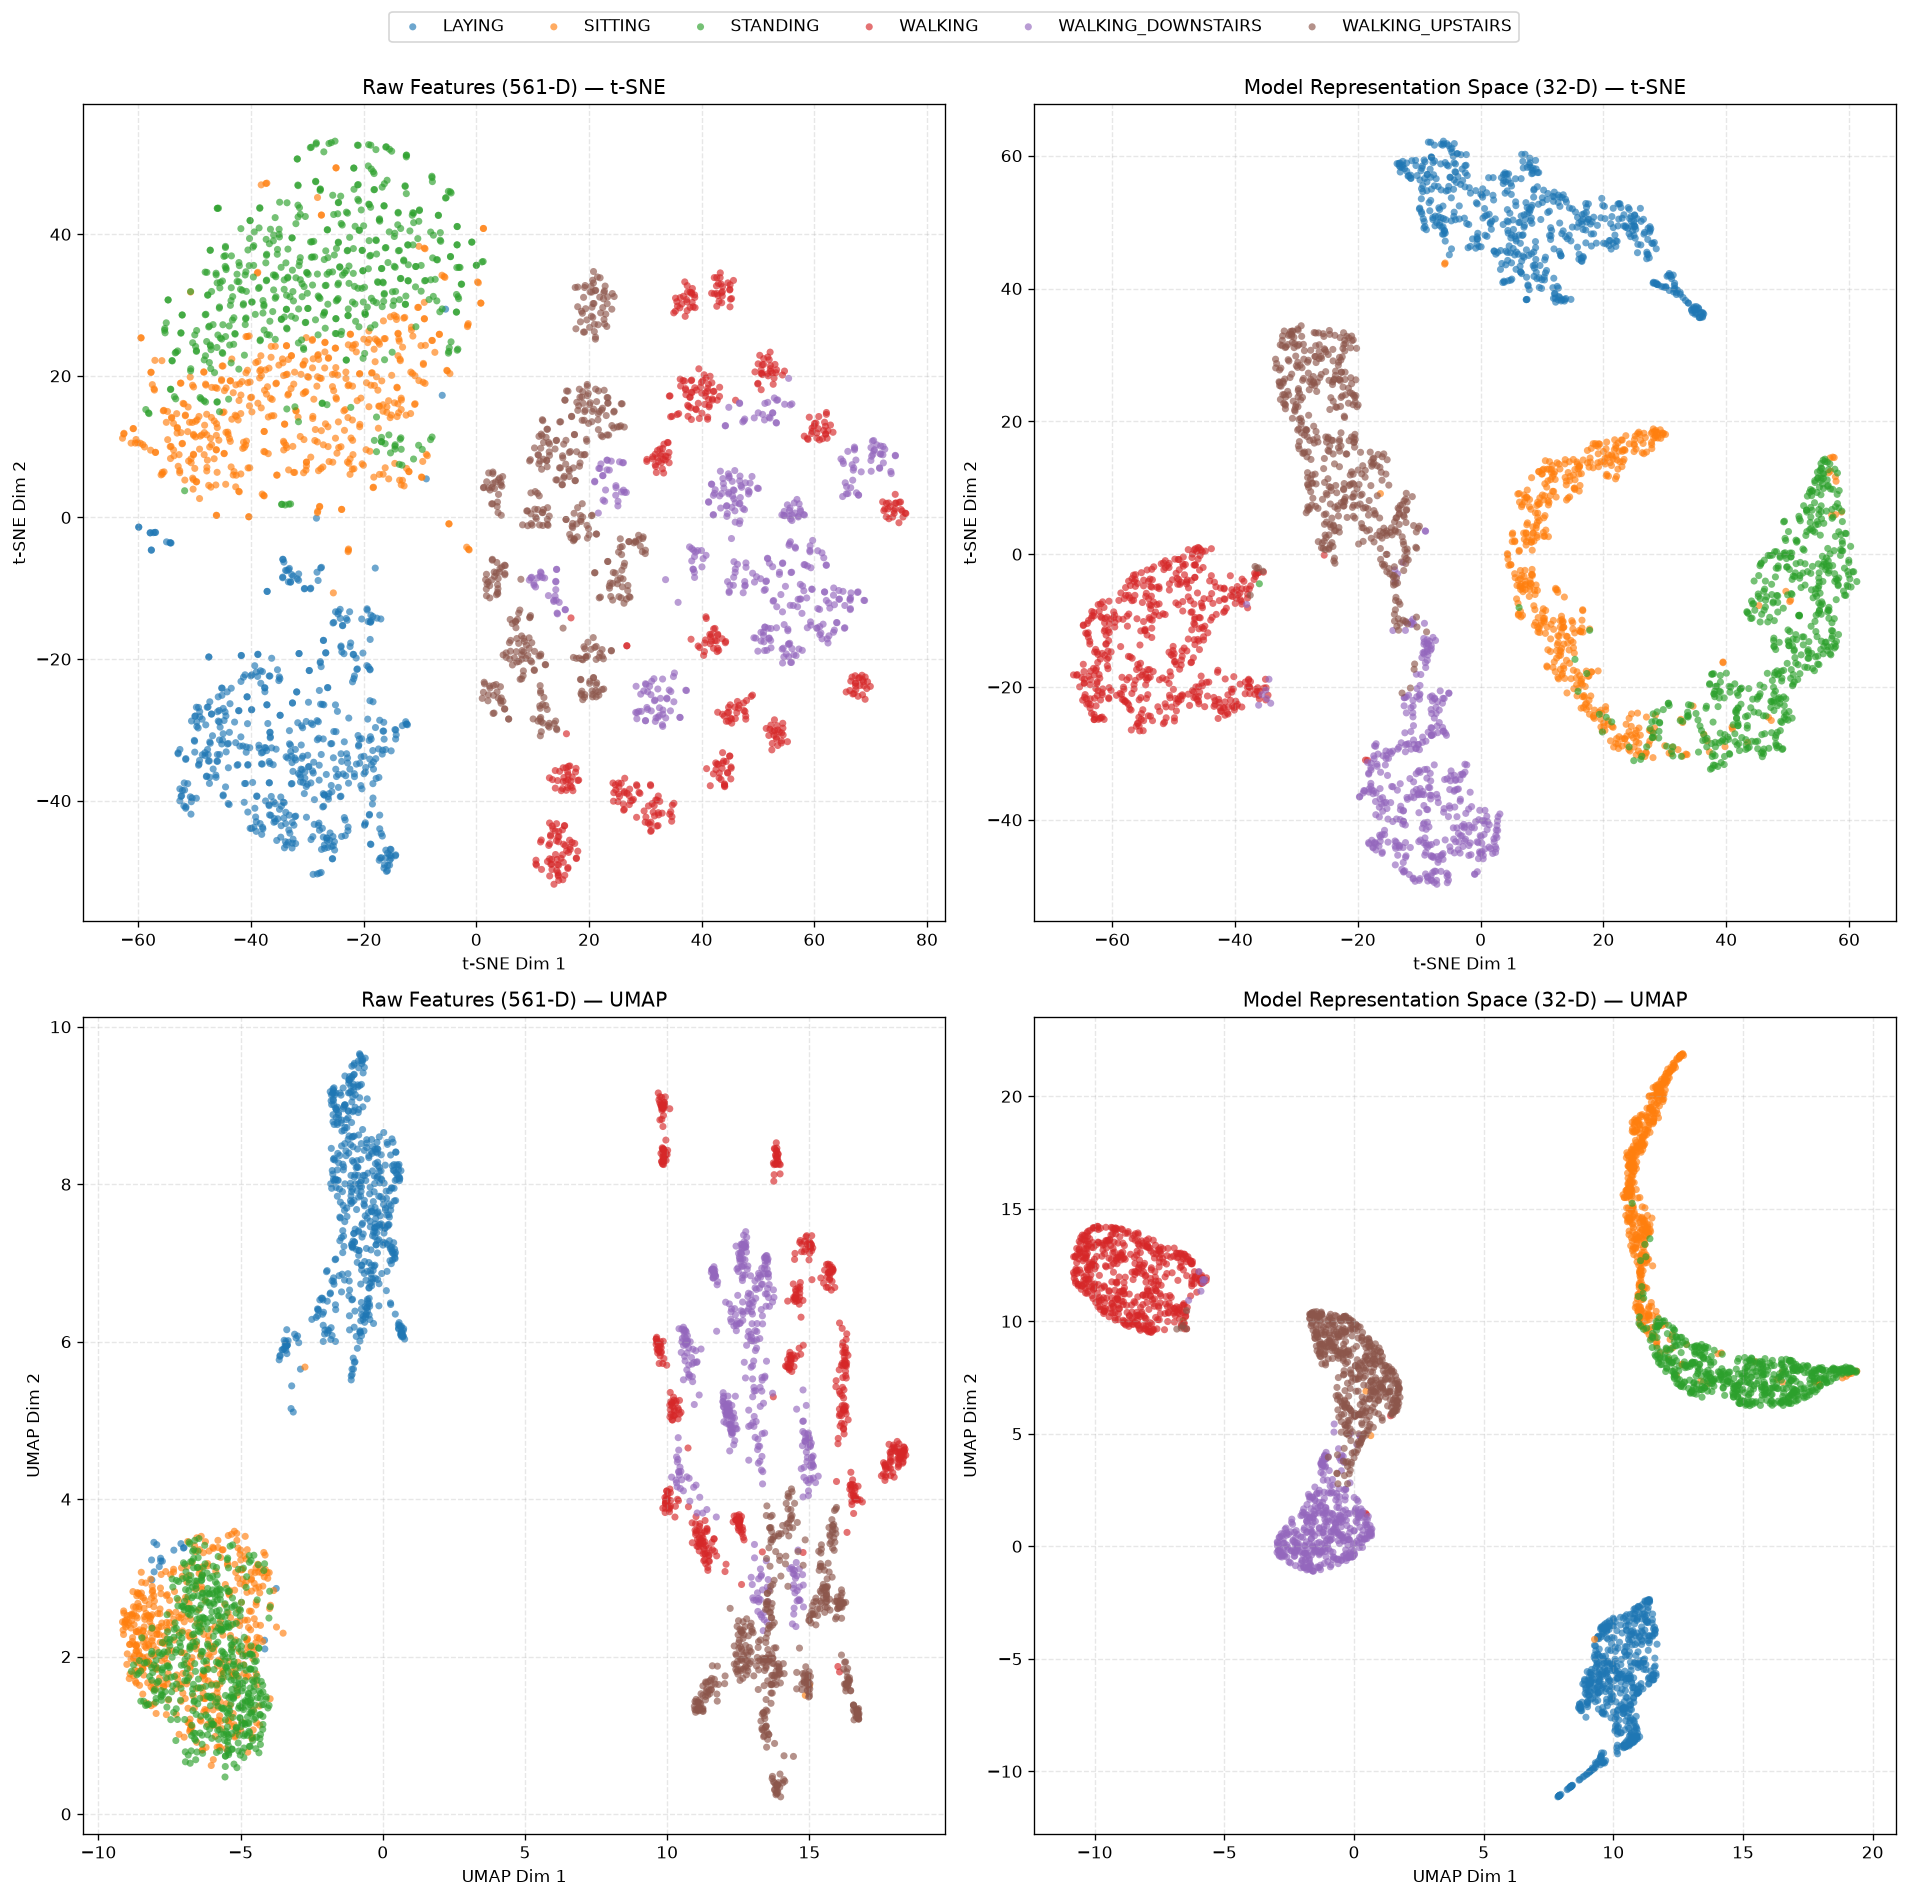

In [36]:
from sklearn.manifold import TSNE
import umap


X_raw = X_test.cpu().numpy()
y_test_np = y_test.cpu().numpy()
y_labels = [idx_to_label[i] for i in y_test_np]

best_model.eval()
penultimate_model = nn.Sequential(*list(best_model.network.children())[:-1])

with torch.no_grad():
    X_latent = penultimate_model(X_test.to(device)).cpu().numpy()

print(f"Raw Input Feature Matrix shape: {X_raw.shape}")
print(f"Model Representation Matrix shape: {X_latent.shape}")


tsne_raw = TSNE(
    n_components=2, perplexity=30, random_state=42, max_iter=1000
).fit_transform(X_raw)

tsne_latent = TSNE(
    n_components=2, perplexity=30, random_state=42, max_iter=1000
).fit_transform(X_latent)


umap_raw = umap.UMAP(
    n_neighbors=30, min_dist=0.3, random_state=42, n_jobs=1
).fit_transform(X_raw)

umap_latent = umap.UMAP(
    n_neighbors=30, min_dist=0.3, random_state=42, n_jobs=1
).fit_transform(X_latent)


fig, axes = plt.subplots(2, 2, figsize=(16, 16), dpi=120)

unique_classes = list(idx_to_label.values())
palette = sns.color_palette("tab10", n_colors=len(unique_classes))
color_map = {cls: palette[i] for i, cls in enumerate(unique_classes)}

plot_configs = [
    (
        axes[0, 0], tsne_raw,
        "Raw Features (561-D) — t-SNE", "t-SNE Dim 1", "t-SNE Dim 2",
    ),
    (
        axes[0, 1], tsne_latent,
        "Model Representation Space (32-D) — t-SNE", "t-SNE Dim 1", "t-SNE Dim 2",
    ),
    (
        axes[1, 0], umap_raw,
        "Raw Features (561-D) — UMAP", "UMAP Dim 1", "UMAP Dim 2",
    ),
    (
        axes[1, 1], umap_latent,
        "Model Representation Space (32-D) — UMAP", "UMAP Dim 1", "UMAP Dim 2",
    ),
]

for ax, coords, title, xlabel, ylabel in plot_configs:
    for cls in unique_classes:
        mask = [lbl == cls for lbl in y_labels]
        ax.scatter(
            coords[mask, 0], coords[mask, 1],
            label=cls, color=color_map[cls], alpha=0.65, s=18, edgecolors="none",
        )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, linestyle="--", alpha=0.3)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center", ncol=6, frameon=True, bbox_to_anchor=(0.5, 0.99),
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

#### Correspondence with the Confusion Matrix

`SITTING` and `STANDING` heavily intermingle. For the raw features, under t-SNE, it almost seem that `SITTING` and `STANDING` are linearly separable while, under UMAP, they overlap. In the latent space projections, the network stretches them apart, but their boundaries remain touching still with a lot of outliers overlapping. This mirrors the confusion matrix, where almost all classification errors stem from confusion between sitting and standing.

`LAYING` is already relatively well-separated in both raw input space and latent representations. This explains its near 100% accuracy.

Dynamic poses (`WALKING`, `UPSTAIRS`, `DOWNSTAIRS`) are well-separated from the static classes as found in the confusion matrix as well. However, within the dynamic cluster, each class form many smaller clusters which intertwine with one another and seems to overlap more in raw features under UMAP.

#### What the Neural Network Changed

**Intra-class Variance Reduction**: In the 561-D raw feature space, data points of the same class are further apart and scattered over different clusters. In the 32-D latent layer, points belonging to the same activity contract into a single compact, well-defined cluster.

**Inter-class Variance Increase**: After the transformation, classes are more separated from eachother. This is most obviously seen with the dynamic activities where `WALKING` and `DOWNSTAIRS` no longer surround `UPSTAIRS`. Note: Distance between clusters may not be representative of the level of separation.

**Non-Linear Transformation**: The successive non-linear transformations project the input into an embedding space where classes are likely linearly separable by the final output layer.

**Capacity**: The model learnt an almost linearly-separable representation. However, some points of one class are still mixed with a different class. This either means that these points are outliers and that the model successfully not overfit on them, that the engineered features are not expressive enough to distinguish between the classes for these cases, or the final 32-D layer is not capable of distinguishing the between the classes. The last one is plausible as we can see some classes are well separated while others touch due to sharing some characteristics that perhaps a higher dimensionality can differentiate. Regardless, this can be verified by looking at the raw sensor data, comparing the latent space of the logistic regression or the shallow network to decide further.

#### Methodological Limitations & Precautions
**Arbitrary Inter-Cluster Distance in t-SNE**: In t-SNE, the distance between two distant clusters is arbitrary and does not represent true level of separation (distances) in high-dimensional space.

**Perplexity and Neighbor Sensitivity**: Setting `perplexity` or `n_neighbors` too low fragments single activities into artificial sub-clusters; setting them too high forces distinct postures together.

**Stochasticity**: Because both t-SNE and UMAP optimize a non-convex layout using gradient descent, seed variations can change the layout, although the neighborhood structure remains fairly invariant.